In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
from pathlib import Path

DATA_PATH = Path("../data/raw/weather.csv")

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")


Dataset loaded successfully!


In [3]:
df.head()


,date,adm_level,adm_id,PCODE,n_pixels,rfh,rfh_avg,r1h,r1h_avg,r3h,r3h_avg,rfq,r1q,r3q,version
0,1/1/1981,2,25830,LK22,67,105.970146,71.977610,NaN,NaN,NaN,NaN,144.159000,NaN,NaN,final
1,1/11/1981,2,25830,LK22,67,7.716418,56.896020,NaN,NaN,NaN,NaN,20.544806,NaN,NaN,final
2,1/21/1981,2,25830,LK22,67,4.328358,54.214924,118.014920,183.08856,NaN,NaN,15.753390,65.402664,NaN,final
3,2/1/1981,2,25830,LK22,67,54.358208,44.043285,66.402985,155.15424,NaN,NaN,121.032290,44.583885,NaN,final
4,2/11/1981,2,25830,LK22,67,3.731343,30.813930,62.417908,129.07214,NaN,NaN,24.379740,50.284798,NaN,final


In [4]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 55590
Number of columns: 15


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 55590 entries, 0 to 55589
Data columns (total 15 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   date       55590 non-null  object 
 1   adm_level  55590 non-null  int64  
 2   adm_id     55590 non-null  int64  
 3   PCODE      55590 non-null  object 
 4   n_pixels   55590 non-null  int64  
 5   rfh        55590 non-null  float64
 6   rfh_avg    55590 non-null  float64
 7   r1h        55522 non-null  float64
 8   r1h_avg    55522 non-null  float64
 9   r3h        55318 non-null  float64
 10  r3h_avg    55318 non-null  float64
 11  rfq        55590 non-null  float64
 12  r1q        55522 non-null  float64
 13  r3q        55318 non-null  float64
 14  version    55590 non-null  object 
dtypes: float64(9), int64(3), object(3)
memory usage: 6.4+ MB


In [6]:
df.isnull().sum()

date           0
adm_level      0
adm_id         0
PCODE          0
n_pixels       0
rfh            0
rfh_avg        0
r1h           68
r1h_avg       68
r3h          272
r3h_avg      272
rfq            0
r1q           68
r3q          272
version        0
dtype: int64

In [7]:
df["date"] = pd.to_datetime(df["date"])

print("Date conversion successful!")
print(df["date"].dtype)

Date conversion successful!
datetime64[ns]


In [8]:
print("Number of records:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of records: 55590
Number of columns: 15


In [9]:
print("Administrative levels:")
print(df["adm_level"].value_counts())

print("\nNumber of unique geographical areas:")
print(df["PCODE"].nunique())

print("\nAvailable geographical codes:")
print(df["PCODE"].unique())

Administrative levels:
adm_level
2    40875
1    14715
Name: count, dtype: int64

Number of unique geographical areas:
34

Available geographical codes:
['LK22' 'LK52' 'LK51' 'LK53' 'LK71' 'LK72' 'LK61' 'LK62' 'LK41' 'LK2'
 'LK5' 'LK45' 'LK7' 'LK42' 'LK44' 'LK6' 'LK43' 'LK4' 'LK92' 'LK9' 'LK3'
 'LK91' 'LK8' 'LK31' 'LK33' 'LK1' 'LK32' 'LK81' 'LK82' 'LK11' 'LK12'
 'LK13' 'LK21' 'LK23']


In [10]:
print("Starting date:", df["date"].min())
print("Ending date:", df["date"].max())

Starting date: 1981-01-01 00:00:00
Ending date: 2026-05-21 00:00:00


In [11]:
missing_values = df.isnull().sum()

print(missing_values)

date           0
adm_level      0
adm_id         0
PCODE          0
n_pixels       0
rfh            0
rfh_avg        0
r1h           68
r1h_avg       68
r3h          272
r3h_avg      272
rfq            0
r1q           68
r3q          272
version        0
dtype: int64


In [12]:
print("Total duplicate rows:", df.duplicated().sum())

print(
    "Duplicate geographical area and date combinations:",
    df.duplicated(subset=["PCODE", "date"]).sum()
)

Total duplicate rows: 0
Duplicate geographical area and date combinations: 0


In [13]:
dates = sorted(df["date"].unique())

date_differences = pd.Series(dates).diff().value_counts()

print("Most common observation intervals:")
print(date_differences.head(10))


Most common observation intervals:
10 days    1271
11 days     317
8 days       35
9 days       11
Name: count, dtype: int64


In [14]:
rainfall_columns = [
    "rfh", "rfh_avg",
    "r1h", "r1h_avg",
    "r3h", "r3h_avg",
    "rfq", "r1q", "r3q"
]

df[rainfall_columns].describe().round(2)

,rfh,rfh_avg,r1h,r1h_avg,r3h,r3h_avg,rfq,r1q,r3q
count,55590.00,55590.00,55522.00,55522.00,55318.00,55318.00,55590.00,55522.00,55318.00
mean,55.12,55.52,165.30,166.55,496.03,499.37,100.08,99.99,99.81
std,60.73,37.67,142.59,108.81,324.12,269.77,74.21,56.05,38.78
min,0.00,0.00,0.00,0.00,0.63,4.36,4.80,6.01,6.84
25%,11.46,24.92,54.21,77.23,233.06,263.27,47.73,62.01,74.04
50%,34.15,47.54,126.85,144.33,444.99,476.85,83.05,90.99,95.16
75%,77.76,81.84,238.50,245.38,703.73,717.22,130.51,126.68,120.02
max,586.07,170.37,1152.42,462.62,2318.96,1209.54,897.56,631.95,452.87


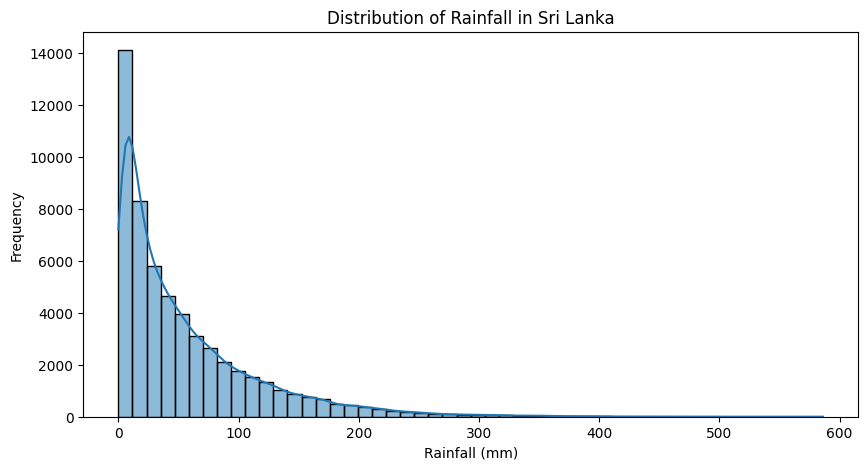

In [15]:
plt.figure(figsize=(10, 5))

sns.histplot(data=df, x="rfh", bins=50, kde=True)

plt.title("Distribution of Rainfall in Sri Lanka")
plt.xlabel("Rainfall (mm)")
plt.ylabel("Frequency")

plt.show()

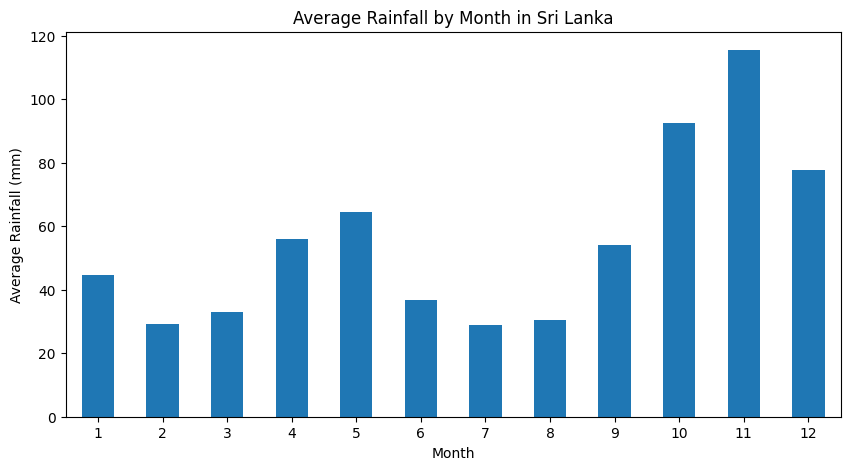

In [16]:
df["month"] = df["date"].dt.month

monthly_rainfall = df.groupby("month")["rfh"].mean()

plt.figure(figsize=(10, 5))

monthly_rainfall.plot(kind="bar")

plt.title("Average Rainfall by Month in Sri Lanka")
plt.xlabel("Month")
plt.ylabel("Average Rainfall (mm)")
plt.xticks(rotation=0)

plt.show()

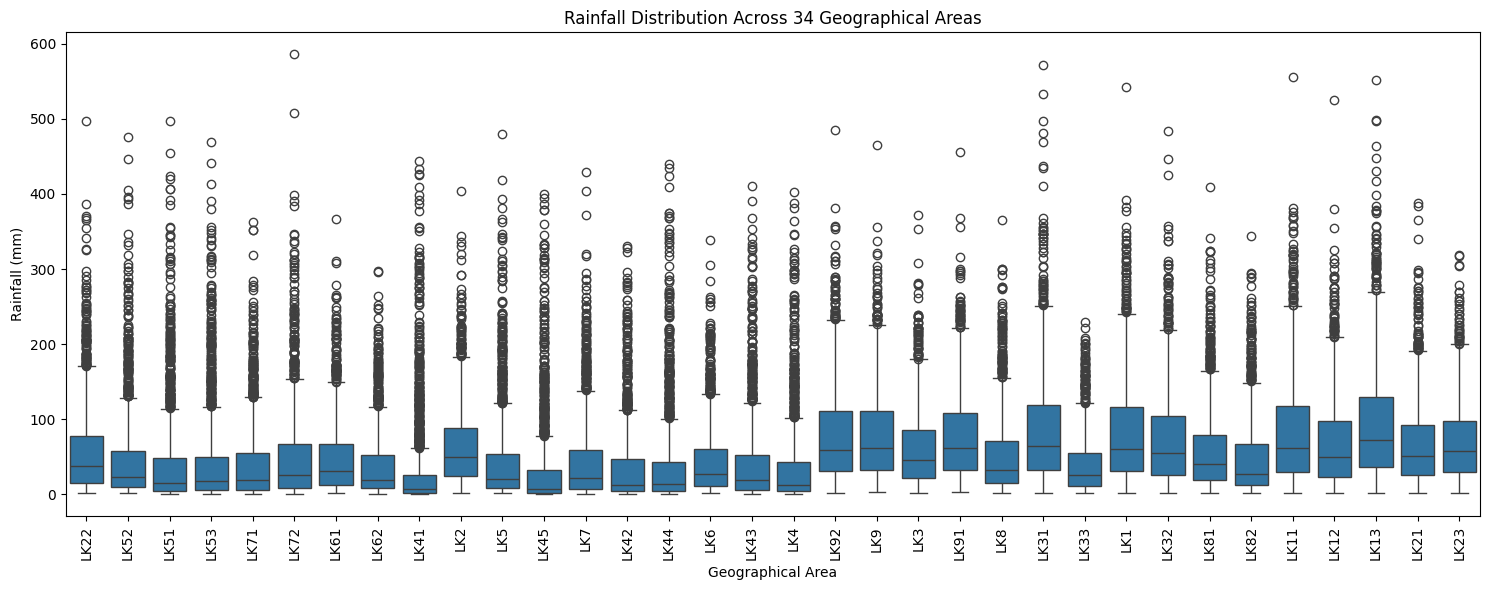

In [17]:
plt.figure(figsize=(15, 6))

sns.boxplot(data=df, x="PCODE", y="rfh")

plt.title("Rainfall Distribution Across 34 Geographical Areas")
plt.xlabel("Geographical Area")
plt.ylabel("Rainfall (mm)")
plt.xticks(rotation=90)

plt.tight_layout()
plt.show()

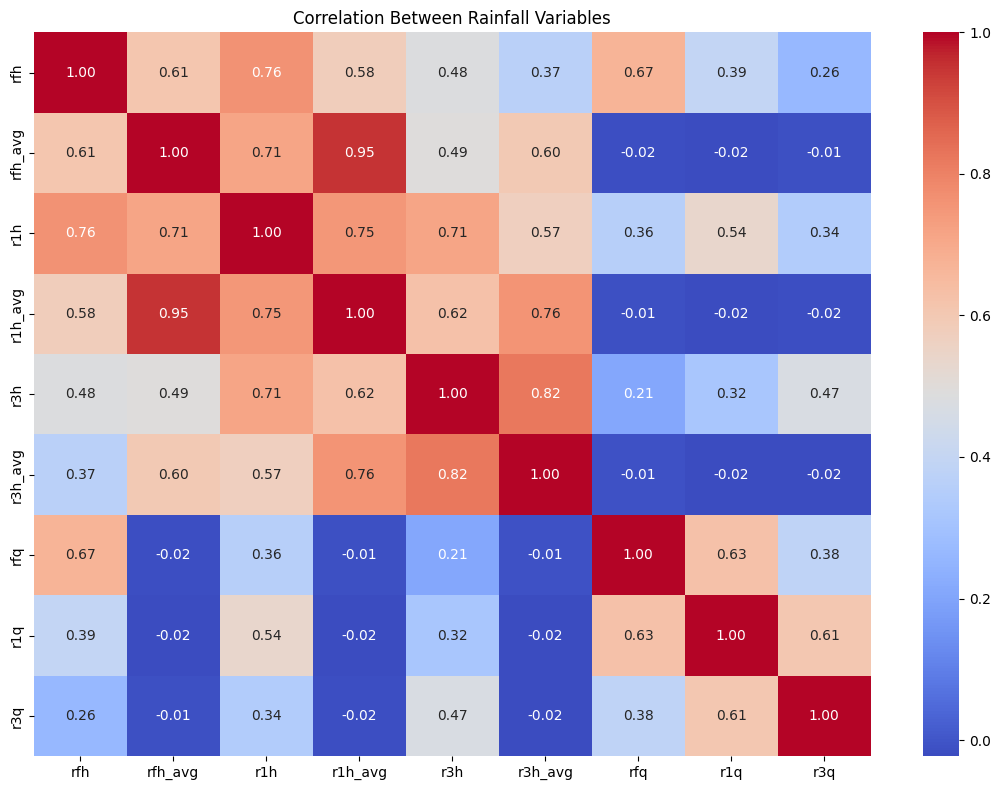

In [18]:
rainfall_columns = [
    "rfh", "rfh_avg",
    "r1h", "r1h_avg",
    "r3h", "r3h_avg",
    "rfq", "r1q", "r3q"
]

plt.figure(figsize=(11, 8))

sns.heatmap(
    df[rainfall_columns].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Between Rainfall Variables")

plt.tight_layout()
plt.show()

In [19]:
print("Administrative level counts:")
print(df["adm_level"].value_counts())

print("\nRainfall records by geographical area:")
print(df.groupby("PCODE")["rfh"].count().describe())

Administrative level counts:
adm_level
2    40875
1    14715
Name: count, dtype: int64

Rainfall records by geographical area:
count      34.0
mean     1635.0
std         0.0
min      1635.0
25%      1635.0
50%      1635.0
75%      1635.0
max      1635.0
Name: rfh, dtype: float64


## Feature engineering

In [20]:
# create a copy
weather_df = df.copy()

weather_df["date"] = pd.to_datetime(weather_df["date"])

weather_df = weather_df.sort_values(
    ["PCODE", "date"]
).reset_index(drop=True)

print("Dataset prepared successfully!")

Dataset prepared successfully!


In [21]:
# Sort observations by geographical area and date
weather_df = weather_df.sort_values(
    ["PCODE", "date"]
).reset_index(drop=True)

# Create historical rainfall features separately for each area
grouped = weather_df.groupby("PCODE")["rfh"]

weather_df["rfh_current"] = grouped.shift(0)
weather_df["rfh_lag_1"] = grouped.shift(1)
weather_df["rfh_lag_2"] = grouped.shift(2)
weather_df["rfh_lag_5"] = grouped.shift(5)

# Predict rainfall in the next observation period
weather_df["target_rainfall"] = grouped.shift(-1)

# Obtain the next observation date
weather_df["target_date"] = (
    weather_df.groupby("PCODE")["date"].shift(-1)
)

# Extract the month of the target observation
weather_df["month"] = weather_df["target_date"].dt.month

print("Feature engineering completed!")

Feature engineering completed!


In [22]:
print(weather_df.columns.tolist())

['date', 'adm_level', 'adm_id', 'PCODE', 'n_pixels', 'rfh', 'rfh_avg', 'r1h', 'r1h_avg', 'r3h', 'r3h_avg', 'rfq', 'r1q', 'r3q', 'version', 'month', 'rfh_current', 'rfh_lag_1', 'rfh_lag_2', 'rfh_lag_5', 'target_rainfall', 'target_date']


In [23]:
weather_df[
    [
        "PCODE",
        "date",
        "rfh_current",
        "rfh_lag_1",
        "rfh_lag_2",
        "rfh_lag_5",
        "target_date",
        "target_rainfall"
    ]
].head(10)

,PCODE,date,rfh_current,rfh_lag_1,rfh_lag_2,rfh_lag_5,target_date,target_rainfall
0,LK1,1981-01-01,70.590164,NaN,NaN,NaN,1981-01-11,4.704918
1,LK1,1981-01-11,4.704918,70.590164,NaN,NaN,1981-01-21,3.467213
2,LK1,1981-01-21,3.467213,4.704918,70.590164,NaN,1981-02-01,56.221310
3,LK1,1981-02-01,56.221310,3.467213,4.704918,NaN,1981-02-11,4.614754
4,LK1,1981-02-11,4.614754,56.221310,3.467213,NaN,1981-02-21,11.418033
5,LK1,1981-02-21,11.418033,4.614754,56.221310,70.590164,1981-03-01,25.286884
6,LK1,1981-03-01,25.286884,11.418033,4.614754,4.704918,1981-03-11,15.278688
7,LK1,1981-03-11,15.278688,25.286884,11.418033,3.467213,1981-03-21,66.032780
8,LK1,1981-03-21,66.032780,15.278688,25.286884,56.221310,1981-04-01,76.950820
9,LK1,1981-04-01,76.950820,66.032780,15.278688,4.614754,1981-04-11,33.172130


In [24]:
features = [
    "rfh_current",
    "rfh_lag_1",
    "rfh_lag_2",
    "rfh_lag_5",
    "month",
    "PCODE",
    "adm_level"
]

target = "target_rainfall"

model_df = weather_df.dropna(
    subset=features + [target, "target_date"]
).copy()

print("Original records:", len(weather_df))
print("Records after cleaning:", len(model_df))
print("Removed records:", len(weather_df) - len(model_df))

print("\nRemaining missing values:")
print(model_df[features + [target]].isnull().sum())

Original records: 55590
Records after cleaning: 55386
Removed records: 204

Remaining missing values:
rfh_current        0
rfh_lag_1          0
rfh_lag_2          0
rfh_lag_5          0
month              0
PCODE              0
adm_level          0
target_rainfall    0
dtype: int64


In [25]:
# Sort the dataset by target date
model_df = model_df.sort_values(
    "target_date"
).reset_index(drop=True)

# Get all unique target dates in chronological order
unique_dates = sorted(model_df["target_date"].unique())

# Calculate the 80% split point
split_index = int(len(unique_dates) * 0.80)

split_date = unique_dates[split_index]

# Split into training and testing datasets
train_df = model_df[
    model_df["target_date"] < split_date
].copy()

test_df = model_df[
    model_df["target_date"] >= split_date
].copy()

print("Training records:", len(train_df))
print("Testing records:", len(test_df))

print("\nTraining date range:")
print(train_df["target_date"].min(), "to", train_df["target_date"].max())

print("\nTesting date range:")
print(test_df["target_date"].min(), "to", test_df["target_date"].max())

print("\nSplit date:", split_date)

Training records: 44302
Testing records: 11084

Training date range:
1981-03-01 00:00:00 to 2017-05-01 00:00:00

Testing date range:
2017-05-11 00:00:00 to 2026-05-21 00:00:00

Split date: 2017-05-11 00:00:00


In [26]:
# Define input features
features = [
    "rfh_current",
    "rfh_lag_1",
    "rfh_lag_2",
    "rfh_lag_5",
    "month",
    "PCODE",
    "adm_level"
]

# Create training and testing inputs
X_train = train_df[features].copy()
X_test = test_df[features].copy()

# Create target variables
y_train = train_df["target_rainfall"]
y_test = test_df["target_rainfall"]

# Convert categorical features into string type
for col in ["PCODE", "adm_level"]:
    X_train[col] = X_train[col].astype(str)
    X_test[col] = X_test[col].astype(str)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (44302, 7)
X_test shape: (11084, 7)
y_train shape: (44302,)
y_test shape: (11084,)


In [27]:
print("Training and testing dates overlap:",
      train_df["target_date"].max() >= test_df["target_date"].min())

print("\nTraining target average:", y_train.mean())
print("Testing target average:", y_test.mean())

Training and testing dates overlap: False

Training target average: 53.3151014557269
Testing target average: 62.88967571081749


## Random Forest (Bagging)
It combines multiple decision trees and averages their predictions to improve accuracy and reduce overfitting.

In [28]:
import time

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

In [29]:
# Prepare preprocessing
categorical_features = ["PCODE", "adm_level"]

numerical_features = [
    "rfh_current",
    "rfh_lag_1",
    "rfh_lag_2",
    "rfh_lag_5",
    "month"
]

preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        ),
        (
            "numerical",
            "passthrough",
            numerical_features
        )
    ]
)

In [30]:
# Build the Random Forest model
rf_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            RandomForestRegressor(
                n_estimators=300,
                max_depth=None,
                min_samples_split=2,
                min_samples_leaf=1,
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

In [31]:
# Train the model
start_time = time.time()

rf_model.fit(X_train, y_train)

rf_training_time = time.time() - start_time

print("Random Forest training completed!")
print("Training time:", round(rf_training_time, 2), "seconds")

Random Forest training completed!
Training time: 595.3 seconds


In [32]:
# make predictions
y_pred_rf = rf_model.predict(X_test)

print("First 10 actual values:")
print(y_test.head(10).values)

print("\nFirst 10 predicted values:")
print(y_pred_rf[:10])

First 10 actual values:
[49.025864 71.24138  22.923346 46.735043 62.45     46.067856 47.968086
 46.61682  45.10753  52.731342]

First 10 predicted values:
[44.36048728 72.00904646 35.96358904 55.76247538 48.61363131 44.38952891
 47.3179852  42.11140713 43.96902721 45.97573649]


In [33]:
#Random Forest Evaluation
rf_mae = mean_absolute_error(y_test, y_pred_rf)

rf_rmse = np.sqrt(mean_squared_error(y_test, y_pred_rf))

rf_r2 = r2_score(y_test, y_pred_rf)

print("Random Forest Evaluation")
print("------------------------")
print("MAE:", round(rf_mae, 4))
print("RMSE:", round(rf_rmse, 4))
print("R2 Score:", round(rf_r2, 4))
print("Training Time:", round(rf_training_time, 2), "seconds")

Random Forest Evaluation
------------------------
MAE: 36.4007
RMSE: 54.4462
R2 Score: 0.2949
Training Time: 595.3 seconds


In [34]:
import joblib
import os

os.makedirs("models", exist_ok=True)

joblib.dump(rf_model, "models/random_forest.pkl")

print("Random Forest model saved successfully!")

Random Forest model saved successfully!


## Train XGBoost (Boosting)
### XGBoost builds many trees independently, Boosting builds trees sequentially, with each new tree trying to improve the previous model's errors.

In [35]:
from xgboost import XGBRegressor

In [36]:
xgb_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", XGBRegressor(
        n_estimators=300,
        max_depth=6,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="reg:squarederror",
        random_state=42,
        n_jobs=-1
    ))
])

In [37]:

#Train XGBoost
start_time = time.time()

xgb_model.fit(X_train, y_train)

xgb_training_time = time.time() - start_time

print("XGBoost training completed!")
print("Training time:", round(xgb_training_time, 2), "seconds")

XGBoost training completed!
Training time: 3.25 seconds


In [38]:
y_pred_xgb = xgb_model.predict(X_test)

In [39]:
#XGBoost Evaluation

xgb_mae = mean_absolute_error(y_test, y_pred_xgb)

xgb_rmse = np.sqrt(mean_squared_error(y_test, y_pred_xgb))

xgb_r2 = r2_score(y_test, y_pred_xgb)

print("XGBoost Evaluation")
print("MAE:", round(xgb_mae, 4))
print("RMSE:", round(xgb_rmse, 4))
print("R2 Score:", round(xgb_r2, 4))
print("Training Time:", round(xgb_training_time, 2), "seconds")

XGBoost Evaluation
MAE: 34.2437
RMSE: 51.4821
R2 Score: 0.3696
Training Time: 3.25 seconds


In [40]:
#save
joblib.dump(xgb_model, "models/xgboost.pkl")

print("XGBoost model saved successfully!")

XGBoost model saved successfully!


## LightGBM (Boosting)

In [46]:
from lightgbm import LGBMRegressor
from sklearn.pipeline import Pipeline

lgbm_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LGBMRegressor(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=-1,
        num_leaves=31,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42,
        n_jobs=-1,
        verbosity=-1
    ))
])

print("LightGBM model created successfully!")

LightGBM model created successfully!


#create the model
lgbm_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LGBMRegressor(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=-1,
        num_leaves=31,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42,
        n_jobs=-1,
        verbosity=-1
    ))
])

In [47]:
# Train the model
start_time = time.time()

lgbm_model.fit(X_train, y_train)

lgbm_training_time = time.time() - start_time

print("LightGBM training completed!")
print("Training time:", round(lgbm_training_time, 2), "seconds")

LightGBM training completed!
Training time: 1.54 seconds


In [48]:
#Make predictions
y_pred_lgbm = lgbm_model.predict(X_test)

In [49]:
#evaluate
lgbm_mae = mean_absolute_error(y_test, y_pred_lgbm)

lgbm_rmse = np.sqrt(mean_squared_error(y_test, y_pred_lgbm))

lgbm_r2 = r2_score(y_test, y_pred_lgbm)

print("LightGBM Evaluation")
print("MAE:", round(lgbm_mae, 4))
print("RMSE:", round(lgbm_rmse, 4))
print("R2 Score:", round(lgbm_r2, 4))
print("Training Time:", round(lgbm_training_time, 2), "seconds")

LightGBM Evaluation
MAE: 34.3427
RMSE: 51.5076
R2 Score: 0.369
Training Time: 1.54 seconds


In [50]:
joblib.dump(lgbm_model, "models/lightgbm.pkl")

print("LightGBM model saved successfully!")

LightGBM model saved successfully!


## CatBoost (Boosting).

### CatBoost is another boosting algorithm. It is particularly useful when working with datasets containing categorical features, such as your PCODE and adm_level.

In [51]:
from catboost import CatBoostRegressor

In [52]:
#Create the CatBoost pipeline
cat_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", CatBoostRegressor(
        iterations=300,
        depth=6,
        learning_rate=0.05,
        loss_function="RMSE",
        random_seed=42,
        verbose=0,
        thread_count=-1
    ))
])

In [53]:
start_time = time.time()

cat_model.fit(X_train, y_train)

cat_training_time = time.time() - start_time

print("CatBoost training completed!")
print("Training time:", round(cat_training_time, 2), "seconds")

CatBoost training completed!
Training time: 2.49 seconds


In [54]:
# make predictions
y_pred_cat = cat_model.predict(X_test)

In [55]:
#evaluate CatBoost
cat_mae = mean_absolute_error(y_test, y_pred_cat)

cat_rmse = np.sqrt(mean_squared_error(y_test, y_pred_cat))

cat_r2 = r2_score(y_test, y_pred_cat)

print("CatBoost Evaluation")
print("MAE:", round(cat_mae, 4))
print("RMSE:", round(cat_rmse, 4))
print("R2 Score:", round(cat_r2, 4))
print("Training Time:", round(cat_training_time, 2), "seconds")

CatBoost Evaluation
MAE: 35.0272
RMSE: 52.1662
R2 Score: 0.3527
Training Time: 2.49 seconds


In [56]:
joblib.dump(cat_model, "models/catboost.pkl")

print("CatBoost model saved successfully!")

CatBoost model saved successfully!


## Model comparison


In [57]:
import pandas as pd

results = pd.DataFrame({
    "Model": ["Random Forest", "XGBoost", "LightGBM", "CatBoost"],
    "MAE": [rf_mae, xgb_mae, lgbm_mae, cat_mae],
    "RMSE": [rf_rmse, xgb_rmse, lgbm_rmse, cat_rmse],
    "R2 Score": [rf_r2, xgb_r2, lgbm_r2, cat_r2],
    "Training Time (s)": [
        rf_training_time,
        xgb_training_time,
        lgbm_training_time,
        cat_training_time
    ]
})

results = results.round(4)

print(results)

           Model      MAE     RMSE  R2 Score  Training Time (s)
0  Random Forest  36.4007  54.4462    0.2949           595.2950
1        XGBoost  34.2437  51.4821    0.3696             3.2536
2       LightGBM  34.3427  51.5076    0.3690             1.5375
3       CatBoost  35.0272  52.1662    0.3527             2.4871


In [58]:
best_model = results.loc[results["MAE"].idxmin()]
#We'll use MAE as the primary selection metric because it directly represents the average absolute prediction error in millimetress

print("Best Model Based on MAE:")
print(best_model)

Best Model Based on MAE:
Model                XGBoost
MAE                  34.2437
RMSE                 51.4821
R2 Score              0.3696
Training Time (s)     3.2536
Name: 1, dtype: object


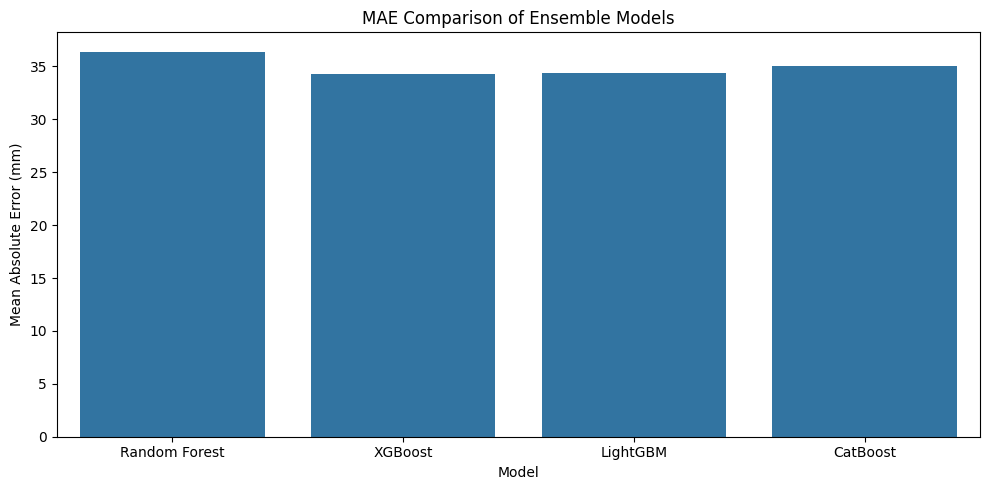

In [59]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))

sns.barplot(data=results, x="Model", y="MAE")

plt.title("MAE Comparison of Ensemble Models")
plt.ylabel("Mean Absolute Error (mm)")
plt.xlabel("Model")
plt.tight_layout()
plt.show()

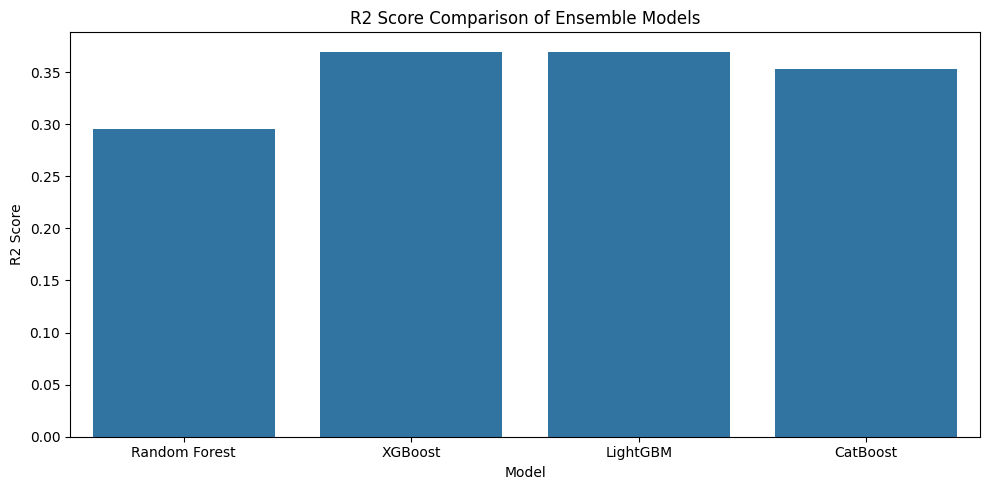

In [60]:
plt.figure(figsize=(10, 5))

sns.barplot(data=results, x="Model", y="R2 Score")

plt.title("R2 Score Comparison of Ensemble Models")
plt.ylabel("R2 Score")
plt.xlabel("Model")
plt.tight_layout()
plt.show()

## Stacking Ensemble

### combine predictions from different models and train another model (called a meta-learner) to learn how to combine them.

In [61]:
from sklearn.model_selection import TimeSeriesSplit
from sklearn.linear_model import Ridge
from sklearn.base import clone

In [62]:
stack_train = train_df.sort_values("target_date").reset_index(drop=True)

X_stack = stack_train[features].copy()
y_stack = stack_train[target].copy()

X_stack["PCODE"] = X_stack["PCODE"].astype(str)
X_stack["adm_level"] = X_stack["adm_level"].astype(str)

dates = stack_train["target_date"].to_numpy()

print("Stacking training data:", X_stack.shape)
print("Unique training dates:", len(np.unique(dates)))

Stacking training data: (44302, 7)
Unique training dates: 1303


In [63]:
#Define the base models
base_models = {
    "Random Forest": Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("model", RandomForestRegressor(
            n_estimators=50,
            max_depth=20,
            min_samples_leaf=2,
            random_state=42,
            n_jobs=-1
        ))
    ]),

    "XGBoost": Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("model", XGBRegressor(
            n_estimators=150,
            max_depth=6,
            learning_rate=0.05,
            subsample=0.8,
            colsample_bytree=0.8,
            objective="reg:squarederror",
            random_state=42,
            n_jobs=-1
        ))
    ]),

    "LightGBM": Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("model", LGBMRegressor(
            n_estimators=150,
            learning_rate=0.05,
            num_leaves=31,
            random_state=42,
            n_jobs=-1,
            verbosity=-1
        ))
    ]),

    "CatBoost": Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("model", CatBoostRegressor(
            iterations=150,
            depth=6,
            learning_rate=0.05,
            loss_function="RMSE",
            random_seed=42,
            verbose=0,
            thread_count=-1
        ))
    ])
}

print("Four base models defined successfully!")

Four base models defined successfully!


In [64]:
#Generate time-series out-of-fold predictions
tscv = TimeSeriesSplit(n_splits=3)

oof_features = []
oof_targets = []

for fold, (train_idx, val_idx) in enumerate(
    tscv.split(np.unique(dates)), start=1
):

    unique_dates = np.unique(dates)

    train_dates = unique_dates[train_idx]
    val_dates = unique_dates[val_idx]

    train_mask = np.isin(dates, train_dates)
    val_mask = np.isin(dates, val_dates)

    X_fold_train = X_stack.loc[train_mask]
    y_fold_train = y_stack.loc[train_mask]

    X_fold_val = X_stack.loc[val_mask]

    fold_predictions = []

    print(f"\nTraining Fold {fold}...")

    for name, model in base_models.items():

        fold_model = clone(model)

        fold_model.fit(X_fold_train, y_fold_train)

        predictions = fold_model.predict(X_fold_val)

        fold_predictions.append(predictions)

        print(f"{name} completed.")

    oof_features.append(
        np.column_stack(fold_predictions)
    )

    oof_targets.append(
        y_stack.loc[val_mask].to_numpy()
    )

print("\nTime-series out-of-fold predictions completed!")


Training Fold 1...
Random Forest completed.
XGBoost completed.
LightGBM completed.
CatBoost completed.

Training Fold 2...
Random Forest completed.
XGBoost completed.
LightGBM completed.
CatBoost completed.

Training Fold 3...
Random Forest completed.
XGBoost completed.
LightGBM completed.
CatBoost completed.

Time-series out-of-fold predictions completed!


In [65]:
#Train the meta-learner
X_meta = np.vstack(oof_features)
y_meta = np.concatenate(oof_targets)

meta_model = Ridge(alpha=1.0)

meta_model.fit(X_meta, y_meta)

print("Meta-learner training completed!")
print("Meta training shape:", X_meta.shape)

Meta-learner training completed!
Meta training shape: (33150, 4)


In [66]:
#rain final base models and predict the test set
stack_fitted_models = {}

final_train_predictions = []

for name, model in base_models.items():

    final_model = clone(model)

    final_model.fit(X_stack, y_stack)

    stack_fitted_models[name] = final_model

    predictions = final_model.predict(X_test)

    final_train_predictions.append(predictions)

    print(name, "final training completed.")

X_test_meta = np.column_stack(final_train_predictions)

y_pred_stack = meta_model.predict(X_test_meta)

print("\nStacking predictions completed!")

Random Forest final training completed.
XGBoost final training completed.
LightGBM final training completed.
CatBoost final training completed.

Stacking predictions completed!


In [67]:
stack_mae = mean_absolute_error(y_test, y_pred_stack)

stack_rmse = np.sqrt(
    mean_squared_error(y_test, y_pred_stack)
)

stack_r2 = r2_score(y_test, y_pred_stack)

print("Stacking Evaluation")
print("MAE:", round(stack_mae, 4))
print("RMSE:", round(stack_rmse, 4))
print("R2 Score:", round(stack_r2, 4))

Stacking Evaluation
MAE: 35.5968
RMSE: 51.3663
R2 Score: 0.3724


In [68]:
joblib.dump(
    {
        "base_models": stack_fitted_models,
        "meta_model": meta_model,
        "features": features
    },
    "models/stacking_model.pkl"
)

print("Stacking model saved successfully!")

Stacking model saved successfully!


## Hybrid Model – Random Forest + ARIMA

In [69]:
#import ARIMA
from statsmodels.tsa.arima.model import ARIMA
import warnings

warnings.filterwarnings("ignore")

In [70]:
#Prepare historical data
train_arima = train_df.copy()
test_arima = test_df.copy()

train_arima = train_arima.sort_values(
    ["PCODE", "target_date"]
)

test_arima = test_arima.sort_values(
    ["PCODE", "date"]
)

print("Training records:", len(train_arima))
print("Testing records:", len(test_arima))
print("Geographical areas:", test_arima["PCODE"].nunique())

Training records: 44302
Testing records: 11084
Geographical areas: 34


In [71]:
arima_predictions = []

for pcode in test_arima["PCODE"].unique():

    area_train = train_arima[
        train_arima["PCODE"] == pcode
    ].sort_values("target_date")

    area_test = test_arima[
        test_arima["PCODE"] == pcode
    ].sort_values("date")

    history = area_train["target_rainfall"].astype(float).tolist()

    try:
        arima_fit = ARIMA(
            history,
            order=(1, 0, 1)
        ).fit()

        previous_date = area_train["target_date"].max()

        area_predictions = []

        for _, row in area_test.iterrows():

            current_date = row["date"]

            # Add newly observed rainfall if it is not already included in the historical series.
            if current_date > previous_date:

                arima_fit = arima_fit.append(
                    [float(row["rfh_current"])],
                    refit=False
                )

                previous_date = current_date

            forecast = arima_fit.forecast(steps=1)[0]

            area_predictions.append(float(forecast))

        arima_predictions.extend(area_predictions)

        print(f"{pcode}: ARIMA completed")

    except Exception as e:
        print(f"{pcode}: ARIMA failed - {e}")
        raise

test_arima = test_arima.sort_values(
    ["PCODE", "date"]
).reset_index(drop=True)

y_pred_arima = np.array(arima_predictions)

print("\nARIMA forecasting completed!")
print("Number of predictions:", len(y_pred_arima))

LK1: ARIMA completed
LK11: ARIMA completed
LK12: ARIMA completed
LK13: ARIMA completed
LK2: ARIMA completed
LK21: ARIMA completed
LK22: ARIMA completed
LK23: ARIMA completed
LK3: ARIMA completed
LK31: ARIMA completed
LK32: ARIMA completed
LK33: ARIMA completed
LK4: ARIMA completed
LK41: ARIMA completed
LK42: ARIMA completed
LK43: ARIMA completed
LK44: ARIMA completed
LK45: ARIMA completed
LK5: ARIMA completed
LK51: ARIMA completed
LK52: ARIMA completed
LK53: ARIMA completed
LK6: ARIMA completed
LK61: ARIMA completed
LK62: ARIMA completed
LK7: ARIMA completed
LK71: ARIMA completed
LK72: ARIMA completed
LK8: ARIMA completed
LK81: ARIMA completed
LK82: ARIMA completed
LK9: ARIMA completed
LK91: ARIMA completed
LK92: ARIMA completed

ARIMA forecasting completed!
Number of predictions: 11084


In [72]:
#Evaluate ARIMA
arima_mae = mean_absolute_error(
    y_test, y_pred_arima
)

arima_rmse = np.sqrt(
    mean_squared_error(y_test, y_pred_arima)
)

arima_r2 = r2_score(
    y_test, y_pred_arima
)

print("ARIMA Evaluation")
print("MAE:", round(arima_mae, 4))
print("RMSE:", round(arima_rmse, 4))
print("R2 Score:", round(arima_r2, 4))

ARIMA Evaluation
MAE: 53.3113
RMSE: 72.2092
R2 Score: -0.2402


In [73]:
#Create the Hybrid model -  combine the predictions from Random Forest and ARIMA.
rf_predictions = rf_model.predict(X_test)

y_pred_hybrid = (
    0.5 * rf_predictions +
    0.5 * y_pred_arima
)

In [74]:
#evaluate
hybrid_mae = mean_absolute_error(
    y_test, y_pred_hybrid
)

hybrid_rmse = np.sqrt(
    mean_squared_error(y_test, y_pred_hybrid)
)

hybrid_r2 = r2_score(
    y_test, y_pred_hybrid
)

print("Hybrid Random Forest + ARIMA Evaluation")
print("MAE:", round(hybrid_mae, 4))
print("RMSE:", round(hybrid_rmse, 4))
print("R2 Score:", round(hybrid_r2, 4))

Hybrid Random Forest + ARIMA Evaluation
MAE: 41.5803
RMSE: 58.3744
R2 Score: 0.1895


In [75]:
#save
joblib.dump(
    {
        "hybrid_method": "50% Random Forest + 50% ARIMA",
        "arima_order": (1, 0, 1),
        "arima_weight": 0.5,
        "rf_weight": 0.5,
        "arima_predictions": y_pred_arima,
        "hybrid_predictions": y_pred_hybrid
    },
    "models/hybrid_rf_arima.pkl"
)

print("Hybrid model results saved successfully!")

Hybrid model results saved successfully!


In [76]:
#Align the ARIMA predictions as predictions may not correspond to the correct actual rainfall observations.
# Create a dataframe linking each ARIMA prediction to its geographical area and target date

arima_result_df = test_arima[
    ["PCODE", "target_date"]
].copy()

arima_result_df["arima_prediction"] = y_pred_arima

test_result_df = test_df[
    ["PCODE", "target_date", "target_rainfall"]
].copy()

test_result_df["rf_prediction"] = rf_model.predict(X_test)

test_result_df = test_result_df.merge(
    arima_result_df,
    on=["PCODE", "target_date"],
    how="left",
    validate="one_to_one"
)

print("Test records:", len(test_result_df))
print("Missing ARIMA predictions:",
      test_result_df["arima_prediction"].isna().sum())

Test records: 11084
Missing ARIMA predictions: 0


In [77]:
y_test_aligned = test_result_df["target_rainfall"]

y_pred_arima_aligned = test_result_df["arima_prediction"]

arima_mae = mean_absolute_error(
    y_test_aligned, y_pred_arima_aligned
)

arima_rmse = np.sqrt(
    mean_squared_error(y_test_aligned, y_pred_arima_aligned)
)

arima_r2 = r2_score(
    y_test_aligned, y_pred_arima_aligned
)

print("Corrected ARIMA Evaluation")
print("MAE:", round(arima_mae, 4))
print("RMSE:", round(arima_rmse, 4))
print("R2 Score:", round(arima_r2, 4))

Corrected ARIMA Evaluation
MAE: 38.3072
RMSE: 55.504
R2 Score: 0.2673


In [78]:
y_pred_hybrid_aligned = (
    0.5 * test_result_df["rf_prediction"].values
    + 0.5 * y_pred_arima_aligned.values
)

hybrid_mae = mean_absolute_error(
    y_test_aligned, y_pred_hybrid_aligned
)

hybrid_rmse = np.sqrt(
    mean_squared_error(y_test_aligned, y_pred_hybrid_aligned)
)

hybrid_r2 = r2_score(
    y_test_aligned, y_pred_hybrid_aligned
)

print("Corrected Hybrid Evaluation")
print("MAE:", round(hybrid_mae, 4))
print("RMSE:", round(hybrid_rmse, 4))
print("R2 Score:", round(hybrid_r2, 4))

Corrected Hybrid Evaluation
MAE: 36.2229
RMSE: 53.2939
R2 Score: 0.3245


In [79]:
#inal model comparison
final_results = pd.DataFrame({
    "Model": [
        "Random Forest",
        "XGBoost",
        "LightGBM",
        "CatBoost",
        "Stacking",
        "ARIMA",
        "Hybrid RF + ARIMA"
    ],
    "MAE": [
        rf_mae,
        xgb_mae,
        lgbm_mae,
        cat_mae,
        stack_mae,
        arima_mae,
        hybrid_mae
    ],
    "RMSE": [
        rf_rmse,
        xgb_rmse,
        lgbm_rmse,
        cat_rmse,
        stack_rmse,
        arima_rmse,
        hybrid_rmse
    ],
    "R2 Score": [
        rf_r2,
        xgb_r2,
        lgbm_r2,
        cat_r2,
        stack_r2,
        arima_r2,
        hybrid_r2
    ]
})

final_results = final_results.round(4)

print(final_results)

               Model      MAE     RMSE  R2 Score
0      Random Forest  36.4007  54.4462    0.2949
1            XGBoost  34.2437  51.4821    0.3696
2           LightGBM  34.3427  51.5076    0.3690
3           CatBoost  35.0272  52.1662    0.3527
4           Stacking  35.5968  51.3663    0.3724
5              ARIMA  38.3072  55.5040    0.2673
6  Hybrid RF + ARIMA  36.2229  53.2939    0.3245


In [80]:
final_results.to_csv(
    "models/final_model_comparison.csv",
    index=False
)

print("Final comparison saved!")

Final comparison saved!


In [81]:
joblib.dump(
    {
        "hybrid_method": "50% Random Forest + 50% ARIMA",
        "arima_order": (1, 0, 1),
        "arima_weight": 0.5,
        "rf_weight": 0.5,
        "arima_predictions": y_pred_arima_aligned,
        "hybrid_predictions": y_pred_hybrid_aligned,
        "metrics": {
            "MAE": hybrid_mae,
            "RMSE": hybrid_rmse,
            "R2": hybrid_r2
        }
    },
    "models/hybrid_rf_arima.pkl"
)

print("Corrected Hybrid results saved!")

Corrected Hybrid results saved!


##  Hyperparameter tuning

### Tuning XGBoost because it achieved the best MAE. We'll use a separate chronological validation set from the training data, keeping the test set untouched.

In [82]:
#Create a chronological validation split
tuning_df = train_df.sort_values(
    "target_date"
).reset_index(drop=True)

unique_dates = np.sort(
    tuning_df["target_date"].unique()
)

split_index = int(len(unique_dates) * 0.80)

tuning_split_date = unique_dates[split_index]

tuning_train = tuning_df[
    tuning_df["target_date"] < tuning_split_date
].copy()

tuning_val = tuning_df[
    tuning_df["target_date"] >= tuning_split_date
].copy()

X_tune_train = tuning_train[features].copy()
y_tune_train = tuning_train[target]

X_tune_val = tuning_val[features].copy()
y_tune_val = tuning_val[target]

for data in [X_tune_train, X_tune_val]:
    data["PCODE"] = data["PCODE"].astype(str)
    data["adm_level"] = data["adm_level"].astype(str)

print("Tuning training records:", len(X_tune_train))
print("Validation records:", len(X_tune_val))
print("Validation starts:", tuning_split_date)

Tuning training records: 35428
Validation records: 8874
Validation starts: 2010-02-11T00:00:00.000000000


In [83]:
#Train and compare configurations
xgb_configs = [
    {"n_estimators": 200, "max_depth": 4, "learning_rate": 0.05},
    {"n_estimators": 300, "max_depth": 6, "learning_rate": 0.05},
    {"n_estimators": 400, "max_depth": 4, "learning_rate": 0.03},
    {"n_estimators": 300, "max_depth": 8, "learning_rate": 0.03}
]

tuning_results = []

for i, params in enumerate(xgb_configs, start=1):

    print(f"\nTraining configuration {i}: {params}")

    model = Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("model", XGBRegressor(
            **params,
            subsample=0.8,
            colsample_bytree=0.8,
            objective="reg:squarederror",
            random_state=42,
            n_jobs=-1
        ))
    ])

    start_time = time.time()

    model.fit(X_tune_train, y_tune_train)

    predictions = model.predict(X_tune_val)

    elapsed = time.time() - start_time

    mae = mean_absolute_error(y_tune_val, predictions)
    rmse = np.sqrt(mean_squared_error(y_tune_val, predictions))
    r2 = r2_score(y_tune_val, predictions)

    tuning_results.append({
        "Configuration": i,
        "Parameters": str(params),
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2,
        "Training Time": elapsed
    })

tuning_results_df = pd.DataFrame(tuning_results)

print("\nHyperparameter Tuning Results")
print(tuning_results_df.round(4))


Training configuration 1: {'n_estimators': 200, 'max_depth': 4, 'learning_rate': 0.05}

Training configuration 2: {'n_estimators': 300, 'max_depth': 6, 'learning_rate': 0.05}

Training configuration 3: {'n_estimators': 400, 'max_depth': 4, 'learning_rate': 0.03}

Training configuration 4: {'n_estimators': 300, 'max_depth': 8, 'learning_rate': 0.03}

Hyperparameter Tuning Results
   Configuration                                         Parameters      MAE  \
0              1  {'n_estimators': 200, 'max_depth': 4, 'learnin...  36.8349   
1              2  {'n_estimators': 300, 'max_depth': 6, 'learnin...  37.1357   
2              3  {'n_estimators': 400, 'max_depth': 4, 'learnin...  36.8078   
3              4  {'n_estimators': 300, 'max_depth': 8, 'learnin...  37.3041   

      RMSE      R2  Training Time  
0  57.3071  0.2998         1.4343  
1  58.0222  0.2822         2.0602  
2  57.3040  0.2999         1.6626  
3  58.2606  0.2763         2.6820  


In [84]:
best_config_index = tuning_results_df["MAE"].idxmin()

best_config = xgb_configs[best_config_index]

print("Best XGBoost Parameters:")
print(best_config)

Best XGBoost Parameters:
{'n_estimators': 400, 'max_depth': 4, 'learning_rate': 0.03}


In [85]:
#train the best XGBoost configuration using the complete training dataset and evaluate it on the untouched test dataset.
best_xgb_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", XGBRegressor(
        n_estimators=400,
        max_depth=4,
        learning_rate=0.03,
        objective="reg:squarederror",
        random_state=42,
        n_jobs=-1
    ))
])

start_time = time.time()

best_xgb_model.fit(X_train, y_train)

tuning_time = time.time() - start_time

best_xgb_predictions = best_xgb_model.predict(X_test)

best_xgb_mae = mean_absolute_error(
    y_test, best_xgb_predictions
)

best_xgb_rmse = np.sqrt(
    mean_squared_error(y_test, best_xgb_predictions)
)

best_xgb_r2 = r2_score(
    y_test, best_xgb_predictions
)

print("Tuned XGBoost Test Results")
print("--------------------------")
print("MAE:", round(best_xgb_mae, 4))
print("RMSE:", round(best_xgb_rmse, 4))
print("R2:", round(best_xgb_r2, 4))
print("Training time:", round(tuning_time, 2), "seconds")

Tuned XGBoost Test Results
--------------------------
MAE: 34.6044
RMSE: 51.3243
R2: 0.3735
Training time: 1.55 seconds


In [86]:
joblib.dump(
    best_xgb_model,
    "models/tuned_xgboost.pkl"
)

print("Tuned XGBoost model saved successfully!")

Tuned XGBoost model saved successfully!


In [87]:
#Update the saved model comparison CSV
updated_results = pd.DataFrame([
    ["Random Forest", 36.4007, 54.4462, 0.2949],
    ["XGBoost", 34.2437, 51.4821, 0.3696],
    ["Tuned XGBoost", 34.6044, 51.3243, 0.3735],
    ["LightGBM", 34.3427, 51.5076, 0.3690],
    ["CatBoost", 35.0272, 52.1662, 0.3527],
    ["Stacking", 35.5968, 51.3663, 0.3724],
    ["ARIMA", 38.3072, 55.5040, 0.2673],
    ["Hybrid RF + ARIMA", 36.2229, 53.2939, 0.3245]
], columns=["Model", "MAE", "RMSE", "R2"])

updated_results.to_csv(
    "models/final_model_comparison.csv",
    index=False
)

display(updated_results)

,Model,MAE,RMSE,R2
0,Random Forest,36.4007,54.4462,0.2949
1,XGBoost,34.2437,51.4821,0.3696
2,Tuned XGBoost,34.6044,51.3243,0.3735
3,LightGBM,34.3427,51.5076,0.3690
4,CatBoost,35.0272,52.1662,0.3527
5,Stacking,35.5968,51.3663,0.3724
6,ARIMA,38.3072,55.5040,0.2673
7,Hybrid RF + ARIMA,36.2229,53.2939,0.3245


In [88]:
print(sorted(weather_df["PCODE"].unique()))

['LK1', 'LK11', 'LK12', 'LK13', 'LK2', 'LK21', 'LK22', 'LK23', 'LK3', 'LK31', 'LK32', 'LK33', 'LK4', 'LK41', 'LK42', 'LK43', 'LK44', 'LK45', 'LK5', 'LK51', 'LK52', 'LK53', 'LK6', 'LK61', 'LK62', 'LK7', 'LK71', 'LK72', 'LK8', 'LK81', 'LK82', 'LK9', 'LK91', 'LK92']
